# 05 · Capstone: Predictive Modelling Workflow

Executes preregistered plan **section H**. *Question:* do models using calendar information and recent history predict **next-day demand** more accurately than a seasonal-naive baseline?

Design: expanding-window, one-step-ahead rolling-origin evaluation; first origin after 14 training days → **16 forecast origins** (2026-06-15 … 06-30). Models: M0 Naive, M1 Seasonal naive, M2 SARIMA (small grid chosen by AICc *inside each origin*), M3 Ridge (calendar + lag1, alpha by `TimeSeriesSplit(3)` *inside each origin*). No test information is used for any tuning.

In [1]:
import sys, warnings, pathlib, subprocess, hashlib
warnings.filterwarnings("ignore")
ROOT = pathlib.Path.cwd().parent
sys.path.insert(0, str(ROOT / "src"))
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from scipy import stats
from IPython.display import display, Markdown, Image
from rq.config import *
from rq.data import load_raw, add_calendar
from rq import stats_tests as st
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 30)
PAL = {"Event": "#d95f02", "Holiday": "#7570b3", "Regular": "#1b9e77"}
df = add_calendar(load_raw(RAW))
print(f"rows={len(df)}  window={df.date.min().date()} .. {df.date.max().date()}  seed={SEED}")
from rq import capstone as cs, forecasting as fc

rows=30  window=2026-06-01 .. 2026-06-30  seed=20260601


In [2]:
pred = cs.rolling_origin(df); pred.to_csv(TABLES / "05_rolling_origin_predictions.csv", index=False)
print(len(pred), "origins:", pred.date.min().date(), "→", pred.date.max().date())
display(pred.drop(columns=["sarima_spec"]).round(1).head(6))
print("SARIMA spec chosen at origins:", pred.sarima_spec.value_counts().to_dict()); print("Ridge alpha chosen:", pred.ridge_alpha.value_counts().to_dict())

16 origins: 2026-06-15 → 2026-06-30


,date,actual,Naive,SeasonalNaive,SARIMA,Ridge,ridge_alpha
0,2026-06-15,131.0,146.0,126.0,128.7,133.4,1.0
1,2026-06-16,134.0,131.0,129.0,133.6,135.5,1.0
2,2026-06-17,139.0,134.0,132.0,136.6,138.3,1.0
3,2026-06-18,141.0,139.0,135.0,141.5,139.7,0.1
4,2026-06-19,154.0,141.0,148.0,153.6,153.2,1.0
5,2026-06-20,168.0,154.0,160.0,165.6,165.8,1.0


SARIMA spec chosen at origins: {'((1, 0, 0), (0, 1, 0, 7))': 16}
Ridge alpha chosen: {1.0: 10, 0.1: 4, 0.01: 2}


,model,MAE,RMSE,MAPE
0,SARIMA,0.966,1.238,0.655
1,Ridge,1.487,1.747,1.008
2,SeasonalNaive,6.062,6.108,4.098
3,Naive,9.625,11.175,6.422


,model,mae_diff_vs_baseline,ci_low,ci_high,wilcoxon_p
0,Naive,3.562,0.812,6.188,0.038
1,SARIMA,-5.097,-5.441,-4.665,0.000
2,Ridge,-4.575,-5.115,-4.002,0.000


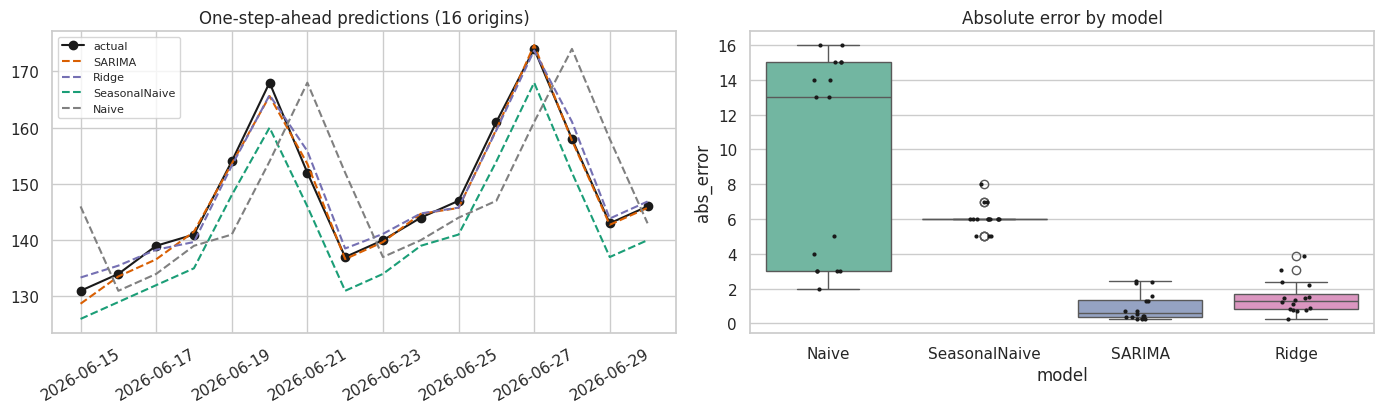

In [3]:
score = cs.score(pred); cmp = cs.paired_vs_baseline(pred)
display(score.round(3)); display(cmp.round(3)); score.round(4).to_csv(TABLES / "05_model_scores.csv", index=False); cmp.round(4).to_csv(TABLES / "05_paired_vs_seasonal_naive.csv", index=False)
fig, ax = plt.subplots(1, 2, figsize=(14, 4.3))
ax[0].plot(pred.date, pred.actual, "k-o", label="actual")
for m, c in [("SARIMA", "#d95f02"), ("Ridge", "#7570b3"), ("SeasonalNaive", "#1b9e77"), ("Naive", "grey")]: ax[0].plot(pred.date, pred[m], "--", color=c, label=m)
ax[0].legend(fontsize=8); ax[0].set_title("One-step-ahead predictions (16 origins)"); ax[0].tick_params(axis="x", rotation=30)
err = pd.melt(pd.DataFrame({m: (pred.actual - pred[m]).abs() for m in ["Naive", "SeasonalNaive", "SARIMA", "Ridge"]}), var_name="model", value_name="abs_error")
sns.boxplot(data=err, x="model", y="abs_error", ax=ax[1], palette="Set2"); sns.stripplot(data=err, x="model", y="abs_error", color="k", size=3, ax=ax[1]); ax[1].set_title("Absolute error by model")
plt.tight_layout(); plt.savefig(FIGS / "05_model_comparison.png", dpi=150); plt.show()

## Interpretable view: Ridge coefficients on all 30 days (standardised features)

,standardised coefficient
dow_0,-3.43
dow_1,-1.13
dow_3,-0.30
dow_2,-0.18
holiday,0.28
dow_6,0.28
dow_4,1.03
event,3.76
dow_5,3.85
lag1,4.33


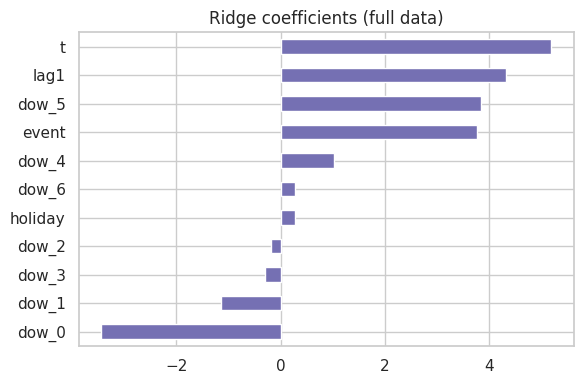

In [4]:
from sklearn.linear_model import Ridge
from sklearn.preprocessing import StandardScaler
Xd = cs.design(df).iloc[1:]; yd = df["demand"].iloc[1:].to_numpy(float)
sc = StandardScaler().fit(Xd); rg = Ridge(alpha=float(pred.ridge_alpha.mode().iloc[0])).fit(sc.transform(Xd), yd)
coef = pd.Series(rg.coef_, index=Xd.columns).sort_values(); display(coef.round(2).to_frame("standardised coefficient"))
fig, ax = plt.subplots(figsize=(6, 4)); coef.plot.barh(ax=ax, color="#7570b3"); ax.set_title("Ridge coefficients (full data)"); plt.tight_layout(); plt.savefig(FIGS / "05_ridge_coef.png", dpi=150); plt.show()
coef.round(4).to_csv(TABLES / "05_ridge_coef.csv")

In [5]:
best = score.iloc[0]; s = score.set_index("model")
simpler_tie = (score.RMSE.iloc[1] - score.RMSE.iloc[0]) / score.RMSE.iloc[0] <= .01
display(Markdown(f"""## Findings

* **Winner by preregistered rule (lowest RMSE over 16 origins): {best.model}** (MAE {best.MAE:.2f}, RMSE {best.RMSE:.2f}, MAPE {best.MAPE:.2f}%). Ridge: RMSE {s.loc['Ridge','RMSE']:.2f}; seasonal-naive: RMSE {s.loc['SeasonalNaive','RMSE']:.2f}; naive: RMSE {s.loc['Naive','RMSE']:.2f}. (Runner-up within 1% RMSE, i.e. tie rule applies: {simpler_tie}.)
* **Versus seasonal-naive baseline (paired, MAE):** SARIMA {cmp.set_index('model').loc['SARIMA','mae_diff_vs_baseline']:.2f} (95% bootstrap CI {cmp.set_index('model').loc['SARIMA','ci_low']:.2f} to {cmp.set_index('model').loc['SARIMA','ci_high']:.2f}), Ridge {cmp.set_index('model').loc['Ridge','mae_diff_vs_baseline']:.2f} (CI {cmp.set_index('model').loc['Ridge','ci_low']:.2f} to {cmp.set_index('model').loc['Ridge','ci_high']:.2f}). Negative = better than baseline. Both clear the baseline decisively; plain naive is *worse* than seasonal-naive.
* **Why:** the series has a strong weekly pattern plus an upward drift of roughly 6–8 units per week. Seasonal-naive repeats last week's value and so is systematically about 6 units too low; SARIMA's seasonal differencing with an AR(1) term, and Ridge's lag-1 + time terms, absorb that drift.
* **Caveats.** 16 origins, strongly autocorrelated errors, and one 30-day series: treat intervals as descriptive. The near-perfect accuracy indicates an unusually regular series; this must be re-checked on longer, noisier data before any operational use.
"""))

## Findings

* **Winner by preregistered rule (lowest RMSE over 16 origins): SARIMA** (MAE 0.97, RMSE 1.24, MAPE 0.65%). Ridge: RMSE 1.75; seasonal-naive: RMSE 6.11; naive: RMSE 11.17. (Runner-up within 1% RMSE, i.e. tie rule applies: False.)
* **Versus seasonal-naive baseline (paired, MAE):** SARIMA -5.10 (95% bootstrap CI -5.44 to -4.67), Ridge -4.58 (CI -5.11 to -4.00). Negative = better than baseline. Both clear the baseline decisively; plain naive is *worse* than seasonal-naive.
* **Why:** the series has a strong weekly pattern plus an upward drift of roughly 6–8 units per week. Seasonal-naive repeats last week's value and so is systematically about 6 units too low; SARIMA's seasonal differencing with an AR(1) term, and Ridge's lag-1 + time terms, absorb that drift.
* **Caveats.** 16 origins, strongly autocorrelated errors, and one 30-day series: treat intervals as descriptive. The near-perfect accuracy indicates an unusually regular series; this must be re-checked on longer, noisier data before any operational use.
